# Unit 9: Membangun Model
**Kode unit:** J.62DMI00.013.1 · SKKNI No. 299 Tahun 2020 · Proyek: *Prediksi Arah Harian IHSG*

**Tujuan unit ini:** melatih model, membandingkannya, dan menyimpan model terbaik.

In [1]:
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 110

In [2]:
import joblib
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

latih = pd.read_csv('../data/processed/latih.csv', parse_dates=['Date'])
FITUR = ['ihsg_chg', 'sp500_chg', 'vix_chg', 'oil_chg', 'gold_chg', 'usdidr_chg']
X, y = latih[FITUR], latih['target']
cv = TimeSeriesSplit(n_splits=5)

## 1. Menyiapkan model

In [3]:
model_list = {
    'Selalu Naik (baseline)': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced')),
    'Decision Tree': DecisionTreeClassifier(max_depth=4, min_samples_leaf=50, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=5, min_samples_leaf=20,
                                            class_weight='balanced', random_state=42),
}

## 2. Validasi silang pada data latih

In [4]:
hasil = []
for nama, model in model_list.items():
    skor = cross_validate(model, X, y, cv=cv, scoring=['accuracy', 'f1_macro', 'roc_auc'])
    hasil.append({'Model': nama,
                  'Accuracy': skor['test_accuracy'].mean(),
                  'F1-macro': skor['test_f1_macro'].mean(),
                  'ROC-AUC': skor['test_roc_auc'].mean()})

# baseline aturan: ikuti arah S&P 500
acc, f1, auc = [], [], []
for _, idx_val in cv.split(X):
    tebak = (X['sp500_chg'].iloc[idx_val] > 0).astype(int)
    acc.append(accuracy_score(y.iloc[idx_val], tebak))
    f1.append(f1_score(y.iloc[idx_val], tebak, average='macro'))
    auc.append(roc_auc_score(y.iloc[idx_val], X['sp500_chg'].iloc[idx_val]))
hasil.append({'Model': 'Ikuti S&P 500 (baseline)', 'Accuracy': np.mean(acc), 'F1-macro': np.mean(f1), 'ROC-AUC': np.mean(auc)})

hasil_cv = pd.DataFrame(hasil).sort_values('Accuracy', ascending=False).reset_index(drop=True)
hasil_cv.round(3)

,Model,Accuracy,F1-macro,ROC-AUC
0,Ikuti S&P 500 (baseline),0.597,0.595,0.633
1,Random Forest,0.594,0.591,0.629
2,Logistic Regression,0.594,0.592,0.634
3,Decision Tree,0.566,0.565,0.602
4,Selalu Naik (baseline),0.542,0.351,0.500


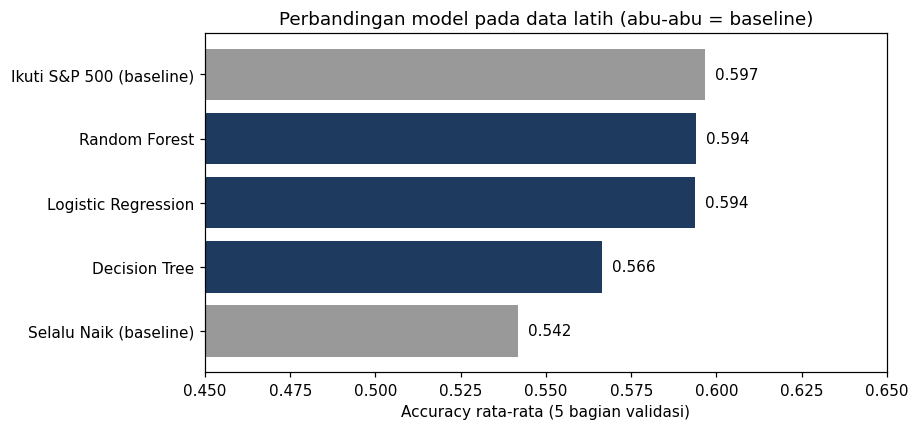

In [5]:
warna = ['#999999' if 'baseline' in m else '#1f3a5f' for m in hasil_cv['Model']]
plt.figure(figsize=(8, 4))
plt.barh(hasil_cv['Model'], hasil_cv['Accuracy'], color=warna)
for i, v in enumerate(hasil_cv['Accuracy']):
    plt.text(v + 0.003, i, f'{v:.3f}', va='center')
plt.gca().invert_yaxis()
plt.xlim(0.45, 0.65)
plt.xlabel('Accuracy rata-rata (5 bagian validasi)')
plt.title('Perbandingan model pada data latih (abu-abu = baseline)')
plt.savefig('../figures/09_perbandingan_model.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. Memilih dan menyimpan model terbaik

In [6]:
kandidat = hasil_cv[~hasil_cv['Model'].str.contains('baseline')]
nama_terbaik = kandidat.iloc[0]['Model']
model_terbaik = model_list[nama_terbaik]
model_terbaik.fit(X, y)            # latih ulang dengan seluruh data latih

joblib.dump(model_terbaik, '../models/model_terbaik.pkl')
with open('../models/info_model.json', 'w') as f:
    json.dump({'model': nama_terbaik, 'fitur': FITUR,
               'cv_accuracy': round(float(kandidat.iloc[0]['Accuracy']), 4)}, f, indent=2)
print('Model terbaik:', nama_terbaik)
print(f"Accuracy validasi silang: {kandidat.iloc[0]['Accuracy']:.3f}")

Model terbaik: Random Forest
Accuracy validasi silang: 0.594


## Kesimpulan
- Random Forest dan Logistic Regression hampir sama baiknya (accuracy validasi ±0,594); Random Forest dipilih dan
  disimpan di `models/model_terbaik.pkl`.
- Catatan jujur: aturan sederhana **"Ikuti S&P 500"** (0,597) sedikit lebih tinggi daripada semua model pada data latih.
  Artinya, sebagian besar kemampuan model berasal dari informasi S&P 500 semalam.
- Kinerja sesungguhnya diuji pada data uji di Unit 10.